# Review triage for a phone-accessories retailer

**BC3415 Individual Assignment, Option A.** A retailer receives thousands of reviews a day, as text and as customer photos. This notebook:
1. classifies each review as **positive / neutral / negative**,
2. detects **what went wrong** (defect, counterfeit, wrong item, shipping damage, performance), and
3. combines the text, metadata and photo signals into a **ranked queue of reviews that point to problematic orders**.

Sections: §1 Data audit · §2 Preprocessing · §3 Models · §4 Explainability · §5 Combining signals · §6 Live demo · §7 Limitations.
Reusable logic (cleaning, issue tagging, flag score) lives in `triage.py`. On the first run, two pretrained models (~1.3 GB) are downloaded.

In [1]:
import io
import json
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          CLIPModel, CLIPProcessor)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import triage

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

LABELS = ["negative", "neutral", "positive"]
COLORS = {"negative": "#eb6834", "neutral": "#8a8984", "positive": "#2a78d6"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
pd.set_option("display.max_colwidth", 160)
START = time.time()

## 1. Data audit

**What:** 9,000 reviews from the *Cell Phones & Accessories* category of Amazon Reviews 2023 (McAuley Lab), with 3,000 per class. They were drawn from a random pool of ~231k reviews by `scripts/build_sample.py`.
**Why:** the labels come from **star ratings, not human annotation**, so we test how trustworthy they are before trusting any metric.
**Look at:** the class imbalance, titles that leak the label, duplicates with conflicting labels, and reviews whose text contradicts their stars.

In [2]:
df = pd.read_csv("data/sample.csv")
df["review_id"] = df.index
with open("data/pool_stats.json") as f:
    pool = json.load(f)

print(f"Pool: {pool['pool_reviews']:,} reviews read from {pool['chunks_read']} random slices "
      f"of the {pool['file_bytes'] / 1e9:.1f} GB {pool['category']} file")
print("Balanced sample:", df.shape)
df[["rating", "label", "title", "text", "n_images", "helpful_vote", "verified_purchase"]].head()

Pool: 231,137 reviews read from 400 random slices of the 9.3 GB Cell_Phones_and_Accessories file
Balanced sample: (9000, 13)


,rating,label,title,text,n_images,helpful_vote,verified_purchase
0,5.0,positive,Quality construction,"It provides me with 2 needed USB ports. I have 3 action cameras, a drone, and photo cameras. the need for charging ports is vital. also don't want to forget...",0,0,True
1,1.0,negative,Don't waste your money!!,It was easy to install and I was even willing to deal with the fact that I had to press my finger harder and sometimes it didn't read my finger print. What ...,0,0,True
2,1.0,negative,A waste!,Absolutely terrible. Offers zero protection and comes apart at the slightest impact.,0,0,True
3,3.0,neutral,"It works well, but it breaks easily","If you want a case for your Pre that protects and also works with your Touchstone, this is the product for you. Be aware though that the clips which hold t...",0,0,True
4,5.0,positive,Good quality,Works perfectly. Lightweight.,0,0,True


          natural pool (%)  balanced sample (%)
negative              19.2                 33.3
neutral                7.3                 33.3
positive              73.5                 33.3


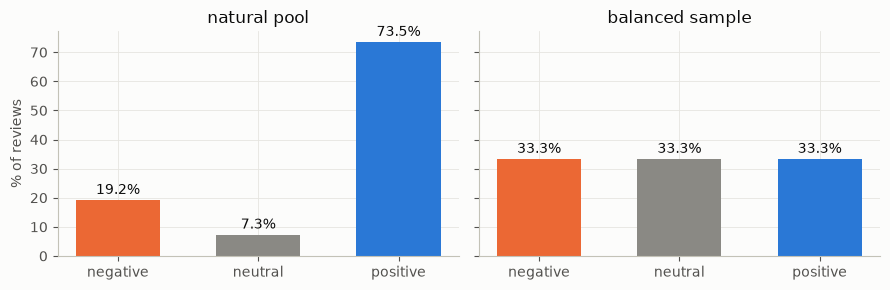

In [3]:
natural = pd.Series(pool["pool_label_counts"]).reindex(LABELS)
balanced = df["label"].value_counts().reindex(LABELS)
shares = pd.DataFrame({
    "natural pool (%)": (100 * natural / natural.sum()).round(1),
    "balanced sample (%)": (100 * balanced / balanced.sum()).round(1),
})
print(shares)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, col in zip(axes, shares.columns):
    bars = ax.bar(LABELS, shares[col], color=[COLORS[l] for l in LABELS], width=0.6)
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.set_title(col.replace(" (%)", ""))
axes[0].set_ylabel("% of reviews")
plt.tight_layout()
plt.show()

In the wild, **neutral (3★) reviews are only 7.3%** of this category and positives are 73.5%. A model trained on that mix could score about 74% accuracy by always predicting "positive" while never finding a neutral review. We therefore **balance to 3,000 per class** and use **macro-F1** as the headline metric, which weights every class equally.
Trade-off: on a balanced test set, precision for the rare neutral class looks better than it would on live traffic. Recall does not depend on class mix, so it carries over.

In [4]:
title = df["title"].fillna("")
text = df["text"].fillna("")
auto_title = title.str.strip().str.match(triage.AUTO_TITLE_PATTERN, case=False)
n_words = (title + " " + text).str.split().str.len()

audit = pd.Series({
    "missing or empty text": (text.str.strip() == "").sum(),
    "missing title": df["title"].isna().sum(),
    "text containing HTML <br /> tags": text.str.contains("<br", regex=False).sum(),
    "auto-generated 'N Stars' title": auto_title.sum(),
    "fewer than 5 words (title + text)": (n_words < 5).sum(),
    "same title+text appears more than once": (title + " " + text).duplicated(keep=False).sum(),
}, name="rows")
audit.to_frame()

,rows
missing or empty text,12
missing title,2
text containing HTML <br /> tags,796
auto-generated 'N Stars' title,896
fewer than 5 words (title + text),483
same title+text appears more than once,90


In [5]:
# Auto titles vs the actual star rating
pd.crosstab(title[auto_title].str.strip().str.title(), df.loc[auto_title, "rating"])

rating,1.0,2.0,3.0,4.0,5.0
title,,,,,
Five Stars,1,0,1,0,315
Four Stars,0,0,0,70,0
One Star,166,0,1,0,0
Three Stars,0,0,281,0,0
Two Stars,1,60,0,0,0


**Leakage found.** When a customer leaves the title blank, Amazon fills it with "Five Stars", "One Star" and so on. These titles **spell out the label**: 896 rows (~10%) have one, and the table shows they agree with the rating almost perfectly. If we left them in, the model would score well by reading the answer. §2 removes them from the model input. The few mismatches (e.g. "Five Stars" on a 1★ review) show the star field itself is not always reliable.

In [6]:
# Candidate label noise: short reviews where VADER sentiment strongly disagrees with the stars.
sia = SentimentIntensityAnalyzer()
clean = text.apply(triage.clean_text)
compound = clean.apply(lambda t: sia.polarity_scores(t)["compound"])
words = clean.str.split().str.len()
low_star_happy = (df["rating"] <= 2) & (compound > 0.7) & words.between(6, 45)
high_star_angry = (df["rating"] >= 4) & (compound < -0.5) & words.between(4, 45)
print("candidates: 1-2 stars but positive text:", low_star_happy.sum(),
      "| 4-5 stars but negative text:", high_star_angry.sum())

# We read the candidates by hand. Many are VADER mistakes (e.g. "my battery was dead by 10am...
# this fixed it"), but these five are real contradictions between stars and text:
NOISE_IDS = [2711, 3112, 5924, 3350, 8147]
df.loc[NOISE_IDS, ["rating", "label", "title", "text"]]

candidates: 1-2 stars but positive text: 63 | 4-5 stars but negative text: 20


,rating,label,title,text
2711,1.0,negative,Perfect,"Was a gift for my son. He says it's great,<br /> aheheres perfectly, and was really easy to install. Hold his phone with a thick case very well, also. Rec..."
3112,2.0,negative,Ok and Portable,It has a small affect but it was affordable. No complaints. It's very portable. I like it best for close-up details rather than the wide-angle option.
5924,5.0,positive,Stopped working! 😡,Stopped working after 3 mos of use! Would not buy again. Save your money and buy something else!
3350,5.0,positive,Product Failure,Feel like the clip is not well made. It broke to quickly for a phone that was not proped up every often. Very disappointed.
8147,5.0,positive,One out of two defective - Seller fixed,UPDATE: Seller sent me a new cable to replace the faulty one at no charge!<br /><br />Only one of the two cords actually worked! The shorter one was defecti...


**The labels are noisy.** #2711 gives 1★ to a review that says "Perfect… Recommend". #5924 ("Stopped working… would not buy again") and #3350 ("Product Failure… Very disappointed") are 5★. #8147 is 5★ because the seller replaced a cable, yet the text reports a defect, which is still worth flagging for triage. Some errors in §3 will therefore be *the label's fault, not the model's*, and no model can reach 100%. We also found reviews filed under the wrong product (#7317 reviews a Star Wars toy inside Cell Phones), a known side effect of Amazon merging product listings.

## 2. Preprocessing

**What:** build one model input per review, **title + text**, with HTML tags and entities removed and the leaky auto-titles dropped. Then remove empty and duplicate inputs and make a stratified 80/20 train/test split.
**Why:** duplicate texts landing in both train and test would let a model "remember" answers, and identical texts with different stars are pure label noise.
**Look at:** how many rows each step removes, and the duplicate groups with conflicting labels.

In [7]:
df["input"] = [triage.make_input(t, x) for t, x in zip(df["title"], df["text"])]
df["n_words"] = df["input"].str.split().str.len()
rows = {"start": len(df)}

df = df[df["input"] != ""]
rows["after dropping empty inputs"] = len(df)

key = df["input"].str.lower()
dups = df[key.duplicated(keep=False)]
groups = dups.groupby(key[dups.index])["label"].agg(copies="size", labels=lambda s: ", ".join(sorted(set(s))))
print(f"{len(dups)} rows share their input with another row ({len(groups)} groups); "
      f"{groups['labels'].str.contains(',').sum()} groups carry conflicting labels")
display(groups.sort_values("copies", ascending=False).head(8))

df = df[~key.duplicated(keep="first")].copy()
rows["after dropping duplicate inputs"] = len(df)
print(pd.Series(rows, name="rows"))
print(df["label"].value_counts())

129 rows share their input with another row (33 groups); 13 groups carry conflicting labels


,copies,labels
input,,
good,13,"neutral, positive"
ok,13,"negative, neutral"
ok. ok,8,"neutral, positive"
its ok,6,"neutral, positive"
excellent,6,positive
good. good,6,"neutral, positive"
nice,6,"neutral, positive"
great,6,"neutral, positive"


start                              9000
after dropping empty inputs        8999
after dropping duplicate inputs    8903
Name: rows, dtype: int64
label
negative    2997
neutral     2960
positive    2946
Name: count, dtype: int64


Removing the auto-titles exposes more duplicates than §1 found: 129 rows now share their input, against 90 before. **13 of the 33 groups carry conflicting labels**: "ok" is labelled both negative and neutral, and "good" both neutral and positive. The same words with different stars is direct proof that star ratings are an imperfect proxy for what the text says. We keep the first copy of each, so no text appears in both train and test. Only 1 review is truly empty once the title is included (the other 11 empty texts have a real title).

In [8]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df, test_df = train_df.copy(), test_df.copy()
print("train:", train_df["label"].value_counts().to_dict())
print("test: ", test_df["label"].value_counts().to_dict())
print(f"short reviews (<5 words) kept: {(df['n_words'] < 5).sum()} - flagged, not removed, because real traffic has them")

train: {'negative': 2397, 'neutral': 2368, 'positive': 2357}
test:  {'negative': 600, 'neutral': 592, 'positive': 589}
short reviews (<5 words) kept: 521 - flagged, not removed, because real traffic has them


## 3. Models

**What:** three approaches of increasing cost. (1) **VADER**, a rule-based lexicon with no training. (2) **TF-IDF (1–2-grams) + Logistic Regression**, trained on our 80%. (3) **Pretrained BERT** (`nlptown/bert-base-multilingual-uncased-sentiment`), used for inference only. It predicts 1–5★, and we sum its probabilities into our 3 classes. We also try (4) **averaging the LR and BERT probabilities**.
**Why:** to see whether training on in-domain data or a large pretrained model is worth its cost.
**Look at:** macro-F1 (headline) and neutral recall, the hardest class.

In [9]:
def vader_label(text):
    compound = sia.polarity_scores(text)["compound"]
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"

test_df["pred_vader"] = test_df["input"].apply(vader_label)

In [10]:
lr_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("lr", LogisticRegression(max_iter=2000)),
])
search = GridSearchCV(lr_pipe, {"lr__C": [0.5, 1, 2, 4, 8]}, scoring="f1_macro", cv=5, n_jobs=2)  # 2 workers keeps RAM low
search.fit(train_df["input"], train_df["label"])
lr_model = search.best_estimator_
print("best C:", search.best_params_["lr__C"], "| 5-fold CV macro-F1:", round(search.best_score_, 3))
print("vocabulary size:", len(lr_model.named_steps["tfidf"].vocabulary_))

assert list(lr_model.classes_) == LABELS
lr_test_probs = lr_model.predict_proba(test_df["input"])
test_df["pred_lr"] = np.array(LABELS)[lr_test_probs.argmax(axis=1)]

best C: 1 | 5-fold CV macro-F1: 0.731
vocabulary size: 31263


In [11]:
BERT_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)
bert = AutoModelForSequenceClassification.from_pretrained(BERT_NAME).eval()

def bert_probs(texts, batch_size=32):
    # Returns [P(negative), P(neutral), P(positive)] per text: 1+2 stars, 3 stars, 4+5 stars.
    texts = list(texts)
    order = np.argsort([len(t) for t in texts])  # batch similar lengths together: less padding, ~3x faster on CPU
    probs = np.zeros((len(texts), 3))
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        batch = bert_tok([texts[j] for j in idx], padding=True, truncation=True,
                         max_length=256, return_tensors="pt")
        with torch.no_grad():
            stars = torch.softmax(bert(**batch).logits, dim=1).numpy()
        probs[idx] = np.column_stack([stars[:, 0] + stars[:, 1], stars[:, 2], stars[:, 3] + stars[:, 4]])
    return probs

t0 = time.time()
bert_test_probs = bert_probs(test_df["input"].tolist())
test_df["pred_bert"] = np.array(LABELS)[bert_test_probs.argmax(axis=1)]
print(f"BERT inference on {len(test_df)} test reviews: {time.time() - t0:.0f}s")

ens_test_probs = (lr_test_probs + bert_test_probs) / 2
test_df["pred_ensemble"] = np.array(LABELS)[ens_test_probs.argmax(axis=1)]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT inference on 1781 test reviews: 201s


In [12]:
def score_row(name, y_true, y_pred):
    p, r, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    row = {"model": name,
           "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro"),
           "accuracy": accuracy_score(y_true, y_pred)}
    for i, label in enumerate(LABELS):
        row[f"{label}_precision"] = p[i]
        row[f"{label}_recall"] = r[i]
    return row

PRED_COLS = {"VADER (lexicon)": "pred_vader", "TF-IDF + LogReg": "pred_lr",
             "BERT nlptown (pretrained)": "pred_bert", "LogReg + BERT average": "pred_ensemble"}
results = pd.DataFrame([score_row(name, test_df["label"], test_df[col]) for name, col in PRED_COLS.items()])
results = results.sort_values("macro_f1", ascending=False).round(3)
os.makedirs("reports", exist_ok=True)
results.to_csv("reports/results.csv", index=False)
results

,model,macro_f1,accuracy,negative_precision,negative_recall,neutral_precision,neutral_recall,positive_precision,positive_recall
3,LogReg + BERT average,0.762,0.774,0.698,0.902,0.778,0.497,0.865,0.922
1,TF-IDF + LogReg,0.746,0.745,0.745,0.757,0.640,0.655,0.855,0.822
2,BERT nlptown (pretrained),0.726,0.748,0.666,0.922,0.784,0.392,0.837,0.930
0,VADER (lexicon),0.467,0.525,0.626,0.567,0.358,0.105,0.500,0.905


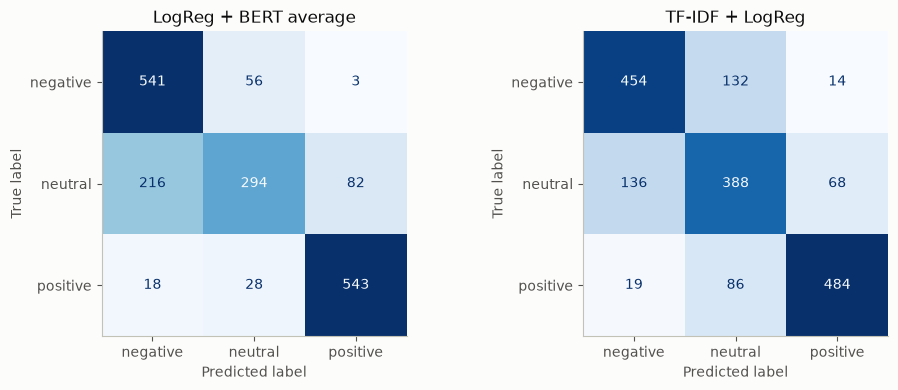

In [13]:
best_two = results["model"].head(2).tolist()  # confusion matrices for the two best models
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, best_two):
    ConfusionMatrixDisplay.from_predictions(test_df["label"], test_df[PRED_COLS[name]], labels=LABELS,
                                            ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

**Results.** Averaging LR and BERT probabilities gives the best **macro-F1 (0.762)**. TF-IDF + LR scores 0.746, BERT alone 0.726, and VADER 0.467.
- **VADER** almost never predicts neutral (recall 0.105), because nearly every review contains some polar word. A general-purpose lexicon is not enough.
- **Neutral is the hard class for every model.** BERT alone recalls only 39.2% of 3★ reviews. LR recalls 65.5% because it learned the hedging vocabulary of *this* data (see §4).
- BERT was never trained on our data yet comes close to LR. nlptown's model was fine-tuned on product reviews, so it has probably seen Amazon-like text, and part of its score is familiarity rather than generalisation.

**Confusion matrices.** The average's main error is calling neutrals negative (216 of 592). LR spreads its errors more evenly. Neither model often confuses positive with negative. **For triage the average makes the right trade-off**: it catches **90.2%** of negative reviews against 75.7% for LR, and a lukewarm review wrongly flagged only costs an agent a few seconds. If the goal were mining lukewarm feedback, LR alone would be the better choice.

## 4. Explainability

**What:** (a) the n-grams that push the Logistic Regression hardest towards each class, read straight from its coefficients. (b) Six test reviews the best model got wrong, each tagged by hand as **label noise** (the stars are wrong) or **model error** (the model is wrong).
**Why:** a retailer will only act on a model whose reasons make sense, and error analysis tells us whether to improve the model or the data.
**Look at:** whether the top words are sensible product language, and how many "errors" are really bad labels.

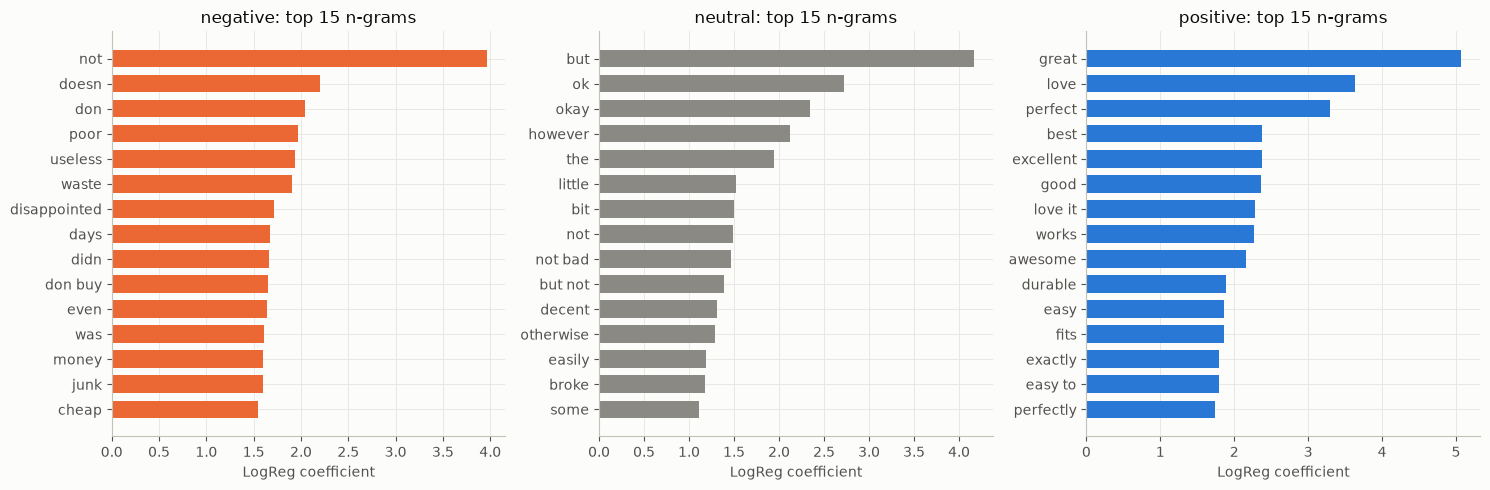

In [14]:
vec = lr_model.named_steps["tfidf"]
clf = lr_model.named_steps["lr"]
terms = np.array(vec.get_feature_names_out())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, i, label in zip(axes, range(3), clf.classes_):
    top = np.argsort(clf.coef_[i])[-15:]
    ax.barh(terms[top], clf.coef_[i][top], color=COLORS[label], height=0.7)
    ax.set_title(f"{label}: top 15 n-grams")
    ax.set_xlabel("LogReg coefficient")
plt.tight_layout()
plt.show()

**What the LR learned is sensible product language.**
- **Negative** is led by "not", "doesn", "don" and "didn" (the tokenizer splits *doesn't* at the apostrophe, so negations survive), plus "waste", "junk", "money", "don buy" and "days" (as in "stopped after 3 days").
- **Neutral** is led by **contrast words**: "but", "however", "otherwise", "not bad", "decent", "a bit / little". A 3★ review is a *hedged* review, and "broke" leans neutral ("works well, but broke…").
- **Positive** is praise plus **fit** words ("fits", "exactly", "perfectly"); for accessories, fitting the phone is what matters.

No "stars" token appears, which confirms that removing the auto-titles worked. "the" in the neutral list is a reminder that coefficients pick up writing style as well as meaning.

In [15]:
best_name = results["model"].iloc[0]
best_col = PRED_COLS[best_name]
wrong = test_df[test_df[best_col] != test_df["label"]]
print(f"{best_name}: {len(wrong)} of {len(test_df)} test reviews misclassified")
examples = wrong.groupby("label").sample(n=2, random_state=SEED)
examples[["review_id", "rating", "label", best_col, "input"]]

LogReg + BERT average: 403 of 1781 test reviews misclassified


,review_id,rating,label,pred_ensemble,input
1229,1229,2.0,negative,neutral,"Works, but still get water underneath. Good product, sturdy and reliable… Already broke my first one… They sent two… I'm already using the back up water doe..."
1921,1921,1.0,negative,neutral,"Some assembly required. Should have come,with instructions, now I have to pay someone to fix my phone"
5500,5500,3.0,neutral,negative,Did not fit SE model. Wow this looks like an excellent product it did not fit my iPhone SE which it said it would
3051,3051,3.0,neutral,negative,"Cheap looking in person. I'm sure this band was great for some, but not for me. It's all one piece, I thought it was two. Quality felt and looked cheap. Ret..."
4288,4288,5.0,positive,negative,Dont Browse Any Further & BUY IT!!!. Dont think about it just BUY IT!!!! By far 1 of the BEST screen protectors for the S6 Edge especially for the price. I ...
5448,5448,5.0,positive,neutral,Serves its purpose.. Some of the USB ports on my PC open to the top. I don't want them to collect dust so I got those protector. They are ridiculously cheap.


In [16]:
# Tagged by hand after reading each review in full
ERROR_TAGS = {
    1229: ("model error", "mixed review: praise first, the complaints (broke, water gets in) come later"),
    1921: ("model error", "clear complaint ('pay someone to fix my phone') with no strongly negative words"),
    5500: ("label noise", "text is a complaint (did not fit the SE as promised) but rated 3 stars"),
    3051: ("label noise", "'quality felt and looked cheap... returned the item' rated 3 stars"),
    4288: ("model error", "enthusiastic review that criticises competing brands along the way"),
    5448: ("model error", "'ridiculously cheap' means low price here, but the model learned cheap = poor quality"),
}
examples["tag"] = examples["review_id"].map(lambda r: ERROR_TAGS[r][0])
examples["why"] = examples["review_id"].map(lambda r: ERROR_TAGS[r][1])
examples[["review_id", "rating", "label", best_col, "tag", "why"]]

,review_id,rating,label,pred_ensemble,tag,why
1229,1229,2.0,negative,neutral,model error,"mixed review: praise first, the complaints (broke, water gets in) come later"
1921,1921,1.0,negative,neutral,model error,clear complaint ('pay someone to fix my phone') with no strongly negative words
5500,5500,3.0,neutral,negative,label noise,text is a complaint (did not fit the SE as promised) but rated 3 stars
3051,3051,3.0,neutral,negative,label noise,'quality felt and looked cheap... returned the item' rated 3 stars
4288,4288,5.0,positive,negative,model error,enthusiastic review that criticises competing brands along the way
5448,5448,5.0,positive,neutral,model error,"'ridiculously cheap' means low price here, but the model learned cheap = poor quality"


**4 of 6 are model errors and 2 are label noise.** The model errors share a pattern: the model reads *words*, not *situations*. It misses a complaint phrased without negative words (#1921), criticism of a competitor inside a 5★ review (#4288), and "cheap" meaning *inexpensive* (#5448). The label-noise cases are 3★ ratings on reviews that read clearly negative. Part of the 22.6% error rate (403 of 1,781) is therefore a ceiling set by the labels, not by the model.

## 5. Combining signals: issue tags + photos → flag queue

**What:** we treat the 1,781 test reviews as "today's intake" and score each one on four signals. (1) The model's P(negative). (2) The worst **issue** found by a keyword tagger (`triage.ISSUE_KEYWORDS`). (3) **Helpful votes**: other shoppers agree. (4) A **CLIP** zero-shot score for whether the customer photo shows a damaged or wrong product.
**Why:** sentiment alone says *a customer is unhappy*, while the queue should say *which orders need action and why*.
**Look at:** the top-20 queue. The weights in `triage.WEIGHTS` are **business assumptions** (no ground-truth "problem order" label exists), so the queue is a ranking aid, not a measured classifier.

In [17]:
test_df["issues"] = test_df["input"].apply(triage.tag_issues)
issue_counts = (test_df.explode("issues")
                .groupby(["issues", "label"]).size().unstack(fill_value=0).reindex(columns=LABELS))
has_issue = test_df["issues"].apply(lambda tags: tags != ["other"])
print("% of reviews with at least one specific issue:",
      (100 * has_issue.groupby(test_df["label"]).mean()).round(1).to_dict())
issue_counts

% of reviews with at least one specific issue: {'negative': 37.3, 'neutral': 20.3, 'positive': 5.1}


label,negative,neutral,positive
issues,,,
counterfeit,3,2,0
damaged_in_shipping,35,19,8
defect_doa,95,44,12
other,376,472,559
performance,91,50,9
wrong_item,11,5,1


The tagger behaves as expected without being trained: a specific issue is found far more often in negative reviews than in positive ones. Defect/DOA and performance complaints dominate. Counterfeit is rare but has the highest severity. Tags in *positive* reviews mostly come from context the keywords cannot see: "these were **not cheaply made**", "the *other* one **cracked**", or a 5★ review that complains the case "DOES NOT FIT" one phone model. That is why the issue signal is combined with P(negative) rather than used alone.

In [18]:
CLIP_NAME = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CLIP_NAME).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
PROMPTS = ["a photo of a damaged, broken or wrong product", "a photo of an intact product in good condition"]

def load_image(url, cache_path=None):
    # Cache the original downloaded bytes, so every run scores exactly the same pixels
    if cache_path and os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            content = f.read()
    else:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        content = response.content
        if cache_path:
            with open(cache_path, "wb") as f:
                f.write(content)
    return Image.open(io.BytesIO(content)).convert("RGB")

def clip_damage_prob(image):
    inputs = clip_proc(text=PROMPTS, images=image, return_tensors="pt", padding=True)
    with torch.no_grad():
        probs = clip(**inputs).logits_per_image.softmax(dim=1)
    return probs[0, 0].item()   # probability of the "damaged" prompt

os.makedirs("data/images", exist_ok=True)
with_photo = test_df[test_df["n_images"] > 0].head(100)
damage, images = {}, {}
for rid, urls in zip(with_photo["review_id"], with_photo["image_urls"]):
    try:
        images[rid] = load_image(urls.split("|")[0], cache_path=f"data/images/{rid}.jpg")
        damage[rid] = clip_damage_prob(images[rid])
    except Exception as err:
        print("skipped", rid, err)
test_df["image_damage"] = test_df["review_id"].map(damage)
print(f"scored {len(damage)} customer photos")
test_df.groupby("label")["image_damage"].agg(["count", "mean"]).round(3)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

scored 100 customer photos


,count,mean
label,,
negative,41,0.631
neutral,32,0.558
positive,27,0.430


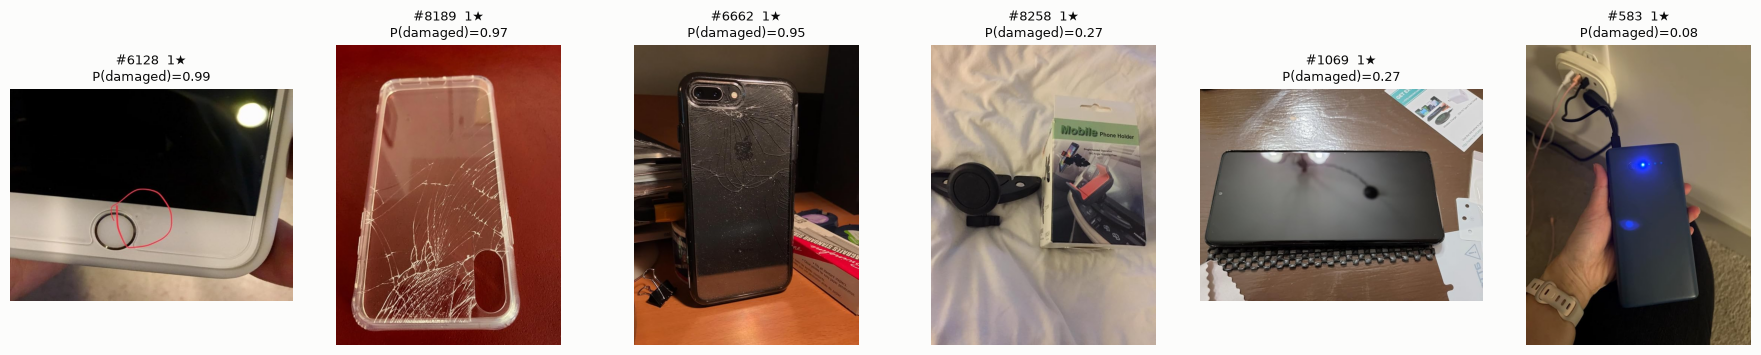

,review_id,rating,image_damage,input
6128,6128,1.0,0.988716,Poor quality control - bubbles in glass. I ordered this product to go with a new phone case I purchased for my mother as a gift. Upon putting the screen cov...
8189,8189,1.0,0.972928,"Update: DO NOT BUY!!!. ******* Update: DO NOT BUY ******* I purchased a transparent one, as my old white one was getting dirty, and white one is no longer a..."
6662,6662,1.0,0.950137,"Does not protect!!!!! Do not buy for iPhone 8's !!!. This is my fifth OtterBox case on various iPhones over the years, always used them have been very satis..."
8258,8258,1.0,0.273792,Not so Magnetic Phone holder. I'm a little disappointed in this product. I was excited to use it in the car. I was selected to review this for free or at a ...
1069,1069,1.0,0.271673,"Mixed feelings. One good install, one failed.. I have mixed feelings about the product. I installed mine first and thought it went super well. I could barel..."
583,583,1.0,0.076616,"Inaccurate color. Color of power bank in photos depicts light blue, actual color is navy blue…"


In [19]:
neg_photos = test_df[test_df["image_damage"].notna() & (test_df["label"] == "negative")]
show = neg_photos.sort_values("image_damage", ascending=False)
show = pd.concat([show.head(3), show.tail(3)])
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, (_, r) in zip(axes, show.iterrows()):
    ax.imshow(images[r["review_id"]])
    ax.set_title(f"#{r['review_id']}  {int(r['rating'])}★\nP(damaged)={r['image_damage']:.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
show[["review_id", "rating", "image_damage", "input"]]

**The image signal is unevaluated.** There are no image labels, so we cannot report its accuracy. One weak sanity check is in the table above: mean P(damaged) is 0.631 on photos attached to negative reviews, 0.558 for neutral and 0.430 for positive. That is the right order, but the gap is modest and it rests on only 100 photos.
- The **3 highest** scores are real damage: a shattered clear case (#8189), a cracked phone back inside a case that "does not protect" (#6662), and a circled bubble under a screen protector (#6128).
- The **3 lowest** show what CLIP *cannot* know. #583 is a wrong-colour complaint (navy instead of light blue), invisible without the product listing photo. #1069 is a failed screen-protector install that does not show at this size.

That is why the photo gets only 10% of the flag score.

In [20]:
TEST_PROBS = {"TF-IDF + LogReg": lr_test_probs, "BERT nlptown (pretrained)": bert_test_probs,
              "LogReg + BERT average": ens_test_probs}
test_df["p_negative"] = TEST_PROBS[best_name][:, 0]   # P(negative) from the best model in §3
queue = triage.build_queue(test_df, top_n=20)
queue[["review_id", "rating", "flag_score", "p_negative", "issues", "helpful_vote", "image_damage", "input"]] \
    .to_csv("reports/flag_queue.csv", index=False)
print("weights (business assumptions):", triage.WEIGHTS)
print("star ratings in the top-20 queue:", queue["rating"].value_counts().sort_index().to_dict())
queue[["review_id", "rating", "flag_score", "p_negative", "issues", "helpful_vote", "image_damage", "input"]].round(3)

weights (business assumptions): {'p_negative': 0.45, 'issue_severity': 0.35, 'helpful_votes': 0.1, 'image_damage': 0.1}
star ratings in the top-20 queue: {1.0: 19, 5.0: 1}


,review_id,rating,flag_score,p_negative,issues,helpful_vote,image_damage,input
8710,8710,1.0,0.877,0.898,defect_doa,28,0.574,Item Defective. The item was defective. The charger prongs were horizontal instead of vertical. Would not buy again from this vendor.
8786,8786,1.0,0.784,0.885,counterfeit,2,NaN,"Cheap and tacky knockoff, SUPER tiny and garish light. Another worthless import from Western Taiwan. This horrible ring light is a joke. It's about the circ..."
1943,1943,1.0,0.775,0.971,defect_doa,1,NaN,"Don't waste ya time folks. Don't waste your money. Worked for a couple uses and then completely quit operating correctly. Lucky for the seller, it stopped w..."
4502,4502,1.0,0.772,0.964,"defect_doa, performance",1,NaN,Poor quality. I didn't even have it a month and it stopped working. No sound.
3814,3814,1.0,0.769,0.958,defect_doa,1,NaN,"This charger just does not work.... It gave me the first charge and I was impressed on how quickly it charged. When I went to charge again, it did not work...."
2291,2291,1.0,0.768,0.840,"counterfeit, performance",0,0.403,Not the same product as advertised on the website and box.. I didn't pay 79 dollars for a cheap flimsy knock off case. It's not even the same as the picture...
2890,2890,1.0,0.766,0.952,defect_doa,1,NaN,"Waste of money.. Did not work in my phones. I have galaxy s7 Edge, galaxy J8 and LGG4. Waste of money."
4419,4419,1.0,0.765,0.661,damaged_in_shipping,364,0.878,"Back of phone shattered-damages cost $549. This fits my iPhone X fine, but the back shattered WHILE this case was on!!! I am so disappointed because it got ..."
8384,8384,1.0,0.759,0.986,defect_doa,0,NaN,Didn't work!!. It did not work. Waste of money!
5924,5924,5.0,0.750,0.966,defect_doa,0,NaN,Stopped working! 😡. Stopped working after 3 mos of use! Would not buy again. Save your money and buy something else!


**Reading the queue.** 19 of the top 20 are 1★ reviews. The exception is **#5924, a 5★ review that says "Stopped working… would not buy again"**, the same label-noise case from §1. Routing by star rating would have missed it; the text-based score catches it.
- Defect/DOA dominates because it is both frequent and high-severity.
- **#4419** has 364 helpful votes, so many shoppers recognised the problem. But it is tagged *damaged in shipping* only because of the word "shattered". It is really a case that failed to protect the phone, which shows a keyword tagger has no sense of context.
- **#8710** ("prongs horizontal instead of vertical") is arguably a *wrong item* (wrong plug type) rather than a defect.

The queue is a prioritisation aid for a human agent, not an automatic refund decision.

## 6. Live demo

**What:** a Gradio app wrapping the whole pipeline. Paste a review (and optionally a photo URL) to get sentiment probabilities, issue tags and the flag score.
**Why:** shows the pipeline is reusable on new, unseen text, not only on our test set.
**Look at:** the cell prints one worked example first, then launches a public `share=True` link. The link only lives while the kernel runs, so any URL saved in this notebook's output is from the last run and has expired.

In [21]:
import gradio as gr

def sentiment_probs(texts):
    # Same model as the headline result in §3
    return (lr_model.predict_proba(texts) + bert_probs(texts)) / 2

def analyse(review_text, image_url="", helpful_votes=0):
    text = triage.clean_text(review_text)
    probs = sentiment_probs([text])[0]
    tags = triage.tag_issues(text)
    image_damage = None
    if image_url and image_url.strip():
        try:
            image_damage = clip_damage_prob(load_image(image_url.strip()))
        except Exception:
            image_damage = None
    score = triage.flag_score(probs[0], tags, helpful_votes, image_damage)
    photo = "no photo" if image_damage is None else f"{image_damage:.2f}"
    return dict(zip(LABELS, probs.round(3).tolist())), ", ".join(tags), round(score, 3), photo

print(analyse("Arrived with a cracked screen protector and the charger stopped working after two days. Looks fake."))

demo = gr.Interface(
    fn=analyse,
    inputs=[gr.Textbox(lines=5, label="Review text"),
            gr.Textbox(label="Customer photo URL (optional)"),
            gr.Number(value=0, label="Helpful votes")],
    outputs=[gr.Label(label="Sentiment"), gr.Textbox(label="Issue tags"),
             gr.Number(label="Flag score (0-1)"), gr.Textbox(label="P(photo shows damage)")],
    examples=[["Great case, fits perfectly and feels solid.", "", 0],
              ["It's okay. Does the job but the color is duller than the picture.", "", 0],
              ["Received the wrong model and the box was crushed. Charger is clearly a knockoff.", "", 3]],
    title="Review triage demo",
)
demo.launch(share=True)

({'negative': 0.926, 'neutral': 0.055, 'positive': 0.019}, 'defect_doa, counterfeit, damaged_in_shipping', np.float64(0.767), 'no photo')


* Running on local URL:  http://127.0.0.1:7860


* Running on public URL: https://96b2f8bd6bc65c39a3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7. Limitations and next steps

| Limitation | Effect | Next step |
|---|---|---|
| Labels are star ratings, not human judgements of the text | Label noise (§1, §4) caps achievable accuracy | Hand-label ~300 test reviews for sentiment to measure the real ceiling |
| Balanced test set | Neutral precision is optimistic: live traffic is only 7.3% neutral | Re-weight the metrics to the natural mix before deployment |
| One category, English only, 2000–2023 reviews | May not transfer to other product lines | Repeat on a second category |
| Sample drawn from 400 random slices of the file | Each slice holds consecutive reviews from the same users, so there is mild clustering | Use more, smaller slices if time allows |
| BERT used off the shelf (no fine-tuning, per the time budget); long reviews truncated at 256 tokens | Weak on neutral; may have seen similar reviews before | Fine-tune on the 7k training reviews |
| Keyword issue tagger | No context or negation ("not defective" still matches); precision/recall unmeasured | Label ~200 negative reviews by issue type and measure it, or replace it with a zero-shot classifier |
| CLIP photo check is zero-shot and unevaluated; it uses only the first photo | Cannot spot a *wrong* item without the listing photo | Compare the customer photo with the product's listing image |
| Flag-score weights are business assumptions | The ranking is a judgement call, not a learned model | Learn the weights from real outcomes (returns, refunds, chargebacks) once they are joined to reviews |

In [22]:
print(f"Notebook run time: {(time.time() - START) / 60:.1f} min")

Notebook run time: 5.2 min
